# Energy-Based Models: sampling from a 2D mixture of Gaussians

An **energy-based model** (EBM) defines a probability density through a scalar *energy* function $E_{\boldsymbol{\theta}}:\mathbb{R}^D\to\mathbb{R}$,

$$
p_{\boldsymbol{\theta}}(\mathbf{x}) = \frac{e^{-E_{\boldsymbol{\theta}}(\mathbf{x})}}{Z_{\boldsymbol{\theta}}},
\qquad Z_\theta = \int e^{-E_{\boldsymbol{\theta}}(\mathbf{x})}\,d\mathbf{x}.
$$

Low energy $\leftrightarrow$ high probability. The normalising constant $Z_\theta$ is intractable, but it is not needed when *contrastive divergence* is used for learning:

* **Sampling** only needs the *force* (the score) $\mathbf{F}_{\boldsymbol{\theta}}(\mathbf{x}) = -\nabla_{\mathbf{x}}E_{\boldsymbol{\theta}}(\mathbf{x}) = \nabla_{\mathbf{x}}\log p_{\boldsymbol{\theta}}(\mathbf{x})$, which does not depend on $Z_{\boldsymbol{\theta}}$. We use **Langevin dynamics**.
* **Training** by maximum likelihood only needs samples from the model (contrastive divergence).

In this notebook we

1. define a target: a mixture of $K$ Gaussians in 2D;
2. Model $E_{\boldsymbol{\theta}}$ with a small multilayer perceptron (MLP), where $\boldsymbol{\theta}$ are the network's synaptic weights;
3. train it with **persistent contrastive divergence** + Langevin MCMC and a replay buffer;
4. compare true and generated samples, overlaid on the **energy landscape** (colormap) and the **force field** (arrows).

**References**

* Y. LeCun et al., *A Tutorial on Energy-Based Learning* (2006). http://yann.lecun.com/exdb/publis/pdf/lecun-06.pdf
* Y. Song & D. P. Kingma, *How to Train Your Energy-Based Models* (2021). https://arxiv.org/abs/2101.03288
* Y. Du & I. Mordatch, *Implicit Generation and Generalization in Energy-Based Models* (2019). https://arxiv.org/abs/1903.08689
* UvA Deep Learning Tutorials, *Tutorial 8: Deep Energy-Based Generative Models*. https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/tutorial8/Deep_Energy_Models.html


**Use AI tools**
* You should try to understand the code and provide answers to the exercises on your own (it is the only way to learn!).
* AI tools can be used to provide hints, assess and improve your answers.
* The use of AI coding tools is allowed. However, you are responsible for the code turned in. This means that you have to understand the code in detail (line by line!) and not only in general terms.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## 1. Target distribution: mixture of $K$ Gaussians

$$
p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k\,\mathcal{N}(\mathbf{x}\mid \boldsymbol{\mu}_k, \sigma^2 \mathbf{I}),
$$

with the means placed on a circle of radius $R$. Because we know $p$ in closed form, we also know the **true energy** $E(\mathbf{x}) = -\log p(\mathbf{x})$ (up to a constant) and the **true force** $-\nabla E(\mathbf{x})$, which we will compare with the learned ones.

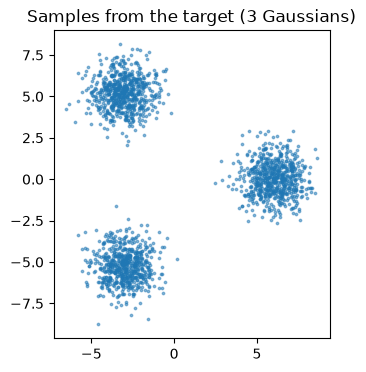

In [2]:
class GaussianMixture2D:
    # Isotropic 2D Gaussian mixture with K components on a circle of radius R.

    def __init__(self, K, radius, std, weights=None):
        angles = torch.arange(K) * 2 * math.pi / K
        self.means = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)  # (K, 2)
        self.std = std
        if weights is None:
            self.weights = torch.full((K,), 1.0 / K)
        else:
            self.weights = torch.as_tensor(weights) / sum(weights)

    def sample(self, n):
        k = torch.multinomial(self.weights, n, replacement=True)
        return self.means[k] + self.std * torch.randn(n, 2)

    def log_prob(self, x):
        # log p(x) computed with logsumexp for numerical stability; x has shape (N, 2).
        means, w = self.means.to(x), self.weights.to(x)
        sq_dist = ((x[:, None, :] - means[None]) ** 2).sum(-1)           # (N, K)
        log_comp = -sq_dist / (2 * self.std**2) - math.log(2 * math.pi * self.std**2)
        return torch.logsumexp(log_comp + torch.log(w), dim=1)

    def energy(self, x):
        return -self.log_prob(x)


K = 3
radius = 6.0
standard_deviation = 1.0
target = GaussianMixture2D(
    K=K,
    radius=radius,
    std=standard_deviation,
    weights=None,
    # weights=[3.0 / 4.0, 3.0 / 16.0, 1.0 / 16.0],
)
x_data = target.sample(20_000)

plt.figure(figsize=(4, 4))
plt.scatter(x_data[:2000, 0], x_data[:2000, 1], s=3, alpha=0.5)
plt.gca().set_aspect("equal"); plt.title(f"Samples from the target ({K} Gaussians)")
plt.show()

## 2. The energy network

$E_\theta$ is an MLP $\mathbb{R}^2\to\mathbb{R}$.
Sice in Langevin dynamics we need $\nabla_{\mathbf{x}}E_\theta$, we use a **smooth** activation, such as the swish (SiLU) function https://en.wikipedia.org/wiki/Swish_function.

Neural networks with ReLU activation functions give piecewise-constant gradients that make poor force fields.

In [3]:
class EnergyNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
         #  nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)   # one scalar energy per point


energy_model = EnergyNet().to(device)
print(sum(p.numel() for p in energy_model.parameters()), "parameters")

17025 parameters


## 3. Sampling with Langevin dynamics

The (unadjusted) Langevin algorithm (ULA) is a Markov chain Monte Carlo (MCMC) method that samples from
$$ p_{\boldsymbol{\theta}}(\mathbf{x}) =  \frac{e^{-E_{\boldsymbol{\theta}}(\mathbf{x})}}{Z_{\boldsymbol{\theta}}}. $$
 using the Markov chain
$$
\mathbf{x}_{t+1} = \mathbf{x}_t - \frac{1}{2} \eta^2 \,\nabla_{\mathbf{x}} E_{\boldsymbol{\theta}}(\mathbf{x}_t) + \eta\,\boldsymbol{\xi}_t,
\qquad \boldsymbol{\xi}_t\sim\mathcal{N}(\mathbf{0},\mathbf{I}),
$$
where $\eta > 0$ is the noise level.

An alternative form of this equation, which is often found in the literature, is
$$
\mathbf{x}_{t+1} = \mathbf{x}_t - ɛ \,\nabla_{\mathbf{x}} E_{\boldsymbol{\theta}}(\mathbf{x}_t) + \sqrt{2 ɛ}\,\boldsymbol{\xi}_t,
\qquad \boldsymbol{\xi}_t\sim\mathcal{N}(\mathbf{0},\mathbf{I}),
$$
where $ ɛ = \frac{1}{2} \eta^2 > 0$ is the step size.

* The first term in this equation corresponds to the force field that drives the chain towards regions of lower energy ("downhill" in energy).

* The second is the noise or diffusion term, which keeps the chain exploring so that it samples $p_{\boldsymbol{\theta}}$ instead of collapsing onto the minima.

For $\eta \to 0^+$ ($\varepsilon \to 0^+$) and $t\to\infty$ the chain generates samples from the exact distribution:
$$ p_{\boldsymbol{\theta}}(\mathbf{x}) =  \frac{e^{-E_{\boldsymbol{\theta}}(\mathbf{x})}}{Z_{\boldsymbol{\theta}}}. $$

References:
* Roberts, G. O., & Tweedie, R. L. (1996). Exponential convergence of Langevin distributions and their discrete approximations. Bernoulli, 2(4), 341–363. https://doi.org/10.2307/3318418
* Welling, M., & Teh, Y. W. (2011). Bayesian Learning via Stochastic Gradient Langevin Dynamics. In Proceedings of the 28th International Conference on Machine Learning (ICML-2011), 681–688. https://www.stats.ox.ac.uk/~teh/research/compstats/WelTeh2011a.pdf

In [4]:
BOX = radius + 3.0 * standard_deviation   # we work in the square [-BOX, BOX]^2

def energy_grad(energy_fn, x):
    """Calculates the energy and its gradient for a given energy function.

    Args:
        energy_fn (callable): The energy function to evaluate.
        x (torch.Tensor): The input tensor for which to calculate energy and gradient.

    Returns:
        tuple: A tuple containing:
            - e (torch.Tensor): The energy values.
            - g (torch.Tensor): The gradients of the energy with respect to x.
    """
    x = x.detach().requires_grad_(True)
    e = energy_fn(x)
    (g,) = torch.autograd.grad(e.sum(), x)
    return e.detach(), g.detach()


def langevin(energy_fn, x, n_steps, noise_level):
    """Performs unadjusted Langevin dynamics to sample from an energy function.

    Args:
        energy_fn (callable): The energy function to sample from.
        x (torch.Tensor): The initial samples (chains).
        n_steps (int): The number of Langevin steps to perform.
        noise_level (float): The noise level (eta) for the Langevin dynamics.

    Returns:
        torch.Tensor: The samples after n_steps of Langevin dynamics.
    """
    for _ in range(n_steps):
        _, g = energy_grad(energy_fn, x)
        x = x - 0.5 * noise_level**2 * g + noise_level * torch.randn_like(x)
        x = x.clamp(-BOX, BOX)
    return x.detach()

## 4. Training: (persistent) contrastive divergence

The negative log-likelihood gradient of an EBM is a difference between two expectations:

$$
\nabla_{\boldsymbol{\theta}} \big(-\log p_{\boldsymbol{\theta}}(\mathbf{x})\big)\Big|_{\text{avg over data}}
= \mathbb{E}_{\mathbf{x}^+\sim p_{\text{data}}}\!\big[\nabla_{\boldsymbol{\theta}} E_{\boldsymbol{\theta}}(\mathbf{x}^+)\big]
- \mathbb{E}_{\mathbf{x}^-\sim p_{\boldsymbol{\theta}}}
\big[\nabla_{\boldsymbol{\theta}} E_{\boldsymbol{\theta}}(\mathbf{x}^-)\big].
$$

To  the surrogate loss, by taking steps along the gradient of
$$
\mathcal{L}(_{\boldsymbol{\theta}}; B) = \frac{1}{|B|}\sum_{i\in B} E_{\boldsymbol{\theta}}(\mathbf{x}^+_i) - \frac{1}{|B|}\sum_{i\in B} E_{\boldsymbol{\theta}}(\mathbf{x}^-_i)
+ \alpha\,\frac{1}{|B|}\sum_{i \in B} \big(E_{\boldsymbol{\theta}}(\mathbf{x}^+_i)^2 + E_{\boldsymbol{\theta}}(\mathbf{x}^-_i)^2\big),
$$
where $B$ is a minibatch of size $|B|$.

Thus, the network weights $\boldsymbol{\theta}$ are modified to
**decrease the energy on the training data** ($\mathbf{x}^+$) and **increase it on generated samples** ($\mathbf{x}^-$). The small $L_2$ term keeps the energy values bounded (as in Du & Mordatch, 2019). **Negative samples** are obtained with a few **Langevin steps** started from a **replay buffer** of previous samples. A small fraction are **re-initialised from uniform noise** so that the chains keep exploring.

**References**:
* Tieleman, T. (2008). Training Restricted Boltzmann Machines Using Approximations to the Likelihood Gradient. In Proceedings of the 25th International Conference on Machine Learning (ICML 2008), 1064–1071. ACM. https://doi.org/10.1145/1390156.1390290
* Yilun Du and Igor Mordatch (2019). Implicit Generation and Modeling with Energy Based Models. In Advances in Neural Information Processing Systems 32 (NeurIPS 2019), 3603–3613. https://arxiv.org/abs/1903.08689


In [5]:
# ---- hyper-parameters ----
n_iters       = 2000
batch_size    = 64
buffer_size   = 10_000
reinit_frac   = 0.05     # fraction of chains restarted from noise at every iteration
n_steps       = 100      # Langevin steps per iteration
noise_level   = 0.1
alpha         = 0.1      # energy-magnitude regulariser
learning_rate = 1e-3

optimizer = torch.optim.Adam(energy_model.parameters(), lr=learning_rate)
data = x_data.to(device)
buffer = (torch.rand(buffer_size, 2, device=device) * 2 - 1) * BOX   # uniform init
history = {"loss": [], "E_pos": [], "E_neg": []}

for it in range(n_iters):
    # positive samples: a minibatch of data
    x_pos = data[torch.randint(len(data), (batch_size,), device=device)]

    # negative samples: take chains from the buffer, restart a few from noise, run Langevin
    idx = torch.randint(buffer_size, (batch_size,), device=device)
    x_init = buffer[idx]
    restart = torch.rand(batch_size, device=device) < reinit_frac
    x_init[restart] = (torch.rand(int(restart.sum()), 2, device=device) * 2 - 1) * BOX
    x_neg = langevin(energy_model, x_init, n_steps=n_steps, noise_level=noise_level)
    buffer[idx] = x_neg

    # contrastive loss
    e_pos, e_neg = energy_model(x_pos), energy_model(x_neg)
    loss = e_pos.mean() - e_neg.mean() + alpha * (e_pos**2 + e_neg**2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    history["loss"].append(loss.item())
    history["E_pos"].append(e_pos.mean().item())
    history["E_neg"].append(e_neg.mean().item())
    if it % 100 == 0:
        print(f"iter {it:5d} of {n_iters:5d} | loss {loss.item():+.3f} | E(data) {e_pos.mean().item():+.3f} | E(model) {e_neg.mean().item():+.3f}")

iter     0 of  2000 | loss -0.028 | E(data) -0.086 | E(model) -0.011
iter   100 of  2000 | loss -1.340 | E(data) -1.438 | E(model) +1.052
iter   200 of  2000 | loss -1.830 | E(data) -1.532 | E(model) +1.708
iter   300 of  2000 | loss -1.686 | E(data) -1.152 | E(model) +1.964
iter   400 of  2000 | loss -1.150 | E(data) -1.135 | E(model) +1.349
iter   500 of  2000 | loss -0.768 | E(data) -1.258 | E(model) +0.538
iter   600 of  2000 | loss -0.916 | E(data) -0.882 | E(model) +0.981
iter   700 of  2000 | loss -0.683 | E(data) -0.820 | E(model) +0.789
iter   800 of  2000 | loss -0.668 | E(data) -0.657 | E(model) +0.752
iter   900 of  2000 | loss -0.872 | E(data) -0.688 | E(model) +0.996
iter  1000 of  2000 | loss -0.646 | E(data) -0.490 | E(model) +0.857
iter  1100 of  2000 | loss -0.566 | E(data) -0.566 | E(model) +0.615
iter  1200 of  2000 | loss -0.848 | E(data) -0.621 | E(model) +0.716
iter  1300 of  2000 | loss -0.558 | E(data) -0.828 | E(model) +0.307
iter  1400 of  2000 | loss -0.439 

At equilibrium, the model samples are distributed like the data, so the average energies of positive and negative samples should become similar so that the contrastive term oscillates around zero.

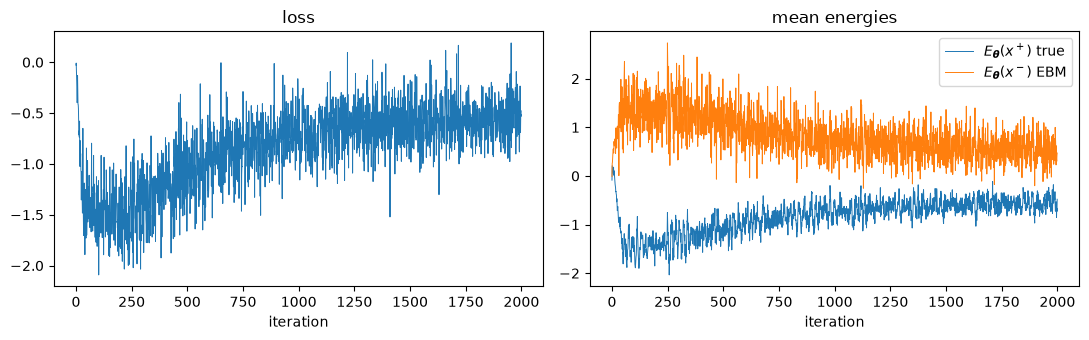

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["loss"], lw=0.7); ax[0].set_title("loss"); ax[0].set_xlabel("iteration")
ax[1].plot(history["E_pos"], lw=0.7, label=r"$E_{\boldsymbol{\theta}}(x^+)$ true")
ax[1].plot(history["E_neg"], lw=0.7, label=r"$E_{\boldsymbol{\theta}}(x^-)$ EBM")
ax[1].set_title("mean energies"); ax[1].set_xlabel("iteration"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Generating new samples

We start fresh chains from **uniform noise** on the box and run a long Langevin chain (the replay buffer is not used here). To reduce the discretisation bias of the unadjusted algorithm we reduce the noise level (annealing) in the final steps.

In [7]:
energy_model.eval() # swith from training to evaluation mode
n_gen = 2000  # number of samples to be gnerate
x_gen = (torch.rand(n_gen, 2, device=device) * 2 - 1) * BOX
x_gen = langevin(energy_model, x_gen, n_steps=1000, noise_level=0.2)
x_gen = langevin(energy_model, x_gen, n_steps=500, noise_level=0.1)
x_gen = langevin(energy_model, x_gen, n_steps=250, noise_level=0.01)

x_gen = x_gen.cpu()
x_true = target.sample(n_gen)

## 6. Energy landscape and force field: true vs. learned

For each distribution we plot

* the **energy** $E(\mathbf{x})$ as a colormap (dark = low energy = high density). The EBM energy is only defined up to an additive constant ($\log Z_{\boldsymbol{\theta}}$), so both energies are shifted to have minimum $0$ on the grid and clipped at the same level for a fair comparison;
* the **force** $\mathbf{F}(\mathbf{x}) = -\nabla_{\mathbf{x}}E(\mathbf{x})$ as arrows. Their magnitudes span orders of magnitude, so arrows are normalised to unit length and coloured by $\log\|\mathbf{F}\|$;
* the samples (true on the left, generated by Langevin on the right).

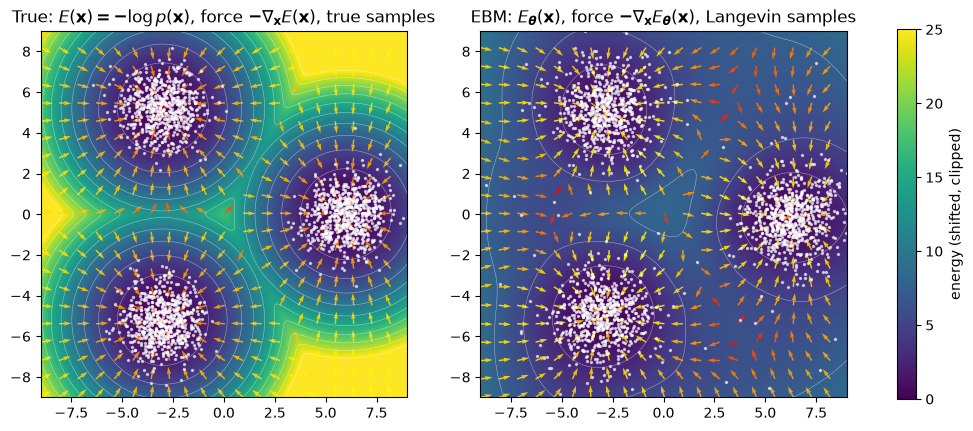

In [8]:
def energy_and_force_on_grid(energy_fn, lim=BOX, n=200):
    # Evaluate E and F = -grad E on an n x n grid.
    xs = torch.linspace(-lim, lim, n)
    X, Y = torch.meshgrid(xs, xs, indexing="xy")
    pts = torch.stack([X.flatten(), Y.flatten()], dim=1).to(device)
    e, g = energy_grad(energy_fn, pts)
    E = e.reshape(n, n).cpu()
    F = (-g).reshape(n, n, 2).cpu()
    return X, Y, E - E.min(), F


def plot_panel(ax, energy_fn, samples, title, e_clip=25.0, arrow_every=10):
    X, Y, E, F = energy_and_force_on_grid(energy_fn)
    im = ax.imshow(E.clamp(max=e_clip), extent=[-BOX, BOX, -BOX, BOX], origin="lower",
                   cmap="viridis", vmin=0, vmax=e_clip)
    ax.contour(X, Y, E, levels=np.linspace(0, e_clip, 11), colors="white", linewidths=0.4, alpha=0.5)

    # force field on a coarser grid
    s = slice(None, None, arrow_every)
    Fx, Fy = F[s, s, 0], F[s, s, 1]
    mag = torch.sqrt(Fx**2 + Fy**2) + 1e-8
    ax.quiver(X[s, s], Y[s, s], Fx / mag, Fy / mag, torch.log(mag),
              cmap="autumn", scale=30, width=0.004, alpha=0.9)

    ax.scatter(samples[:, 0], samples[:, 1], s=2, c="white", alpha=0.6)
    ax.set_xlim(-BOX, BOX); ax.set_ylim(-BOX, BOX); ax.set_aspect("equal")
    ax.set_title(title)
    return im


fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_panel(axes[0], target.energy, x_true, r"True: $E(\mathbf{x})=-\log p(\mathbf{x})$, force $-\nabla_{\mathbf{x}} E(\mathbf{x})$, true samples")
im = plot_panel(axes[1], energy_model, x_gen, r"EBM: $E_{\boldsymbol{\theta}}(\mathbf{x})$, force $-\nabla_{\mathbf{x}} E_{\boldsymbol{\theta}}(\mathbf{x})$, Langevin samples")
fig.colorbar(im, ax=axes, shrink=0.8, label="energy (shifted, clipped)")
plt.show()

- **Modes missing or samples smeared?** Train longer, increase  the number of Langevin steps (`n_steps`), or increase the fraction of chains restarted from noise (`reinit_frac`).

- **Loss diverges / energies explode?** Increase `alpha`, reduce `learning_rate`, or reduce `noise_level`.
- **Samples stuck in a few modes?** Increase `noise_level` a little, or use a larger replay buffer.
- EBM training is inherently less stable than e.g. a VAE, so the loss curve is noisy and not a reliable measure of quality. Use the quality of the samples to determine whether the network is trained correctly.

**What to look for**

* The learned energy has **basins at the mixture means**; the force arrows point towards the nearest mode, with a **watershed** (ridge) between neighbouring modes, as in the true landscape.
* Far from the data the learned energy is less accurate: the model is only trained where the positive and negative samples go. This is a general property of EBMs (and of score-based models).



## 7. A simple quantitative check.

Assign each sample to the nearest component:
*   Compare the proportions assigned to each component with the actual mixture weights.
*   Compare the mean vectors and covariance matrices of each component estimated from the sampls assigned to each component.

The model should neither drop modes (*mode collapse*) nor create spurious ones. Furthermore, the means and the covariance matrices of each component should be similar to the actual ones.

Estimates of the Gaussian component parameters with high-quality samples (within 3σ of a component mean):
true 98.8%, EBM 94.2%

Component weights:
true weights: [0.35 , 0.313, 0.338]
EBM weights:  [0.355, 0.319, 0.325]
Error: 0.0247

Component 0
true mean: [ 6.007, -0.034]
EBM mean:  [ 6.206, -0.17 ]
Error: 0.04
true covariance matrix:
[[0.964, 0.084],
 [0.084, 0.904]]
EBM covariance matrix:
[[1.125, 0.097],
 [0.097, 1.064]]
Error: 0.171

Component 1
true mean: [-3.043,  5.232]
EBM mean:  [-2.896,  5.171]
Error: 0.0264
true covariance matrix:
[[ 0.973, -0.003],
 [-0.003,  0.952]]
EBM covariance matrix:
[[ 1.082, -0.001],
 [-0.001,  1.217]]
Error: 0.21

Component 2
true mean: [-3.02, -5.25]
EBM mean:  [-3.028, -5.   ]
Error: 0.0412
true covariance matrix:
[[0.916, 0.026],
 [0.026, 0.974]]
EBM covariance matrix:
[[1.182, 0.029],
 [0.029, 1.17 ]]
Error: 0.246


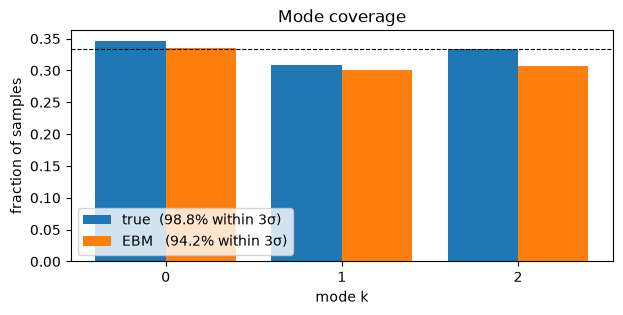

In [9]:
def check_gaussian_mixture(x, means, std, n_std=3.0):
    """Estimate the parameters of each Gaussian component from "high-quality" samples,
    i.e. samples within n_std·σ of the closest component mean.

    Returns
      p_hq       : float      fraction of high-quality samples
      weights_hq : (K,)       fraction of *all* samples assigned to each component
                              (weights_hq.sum() == p_hq; divide by p_hq to get mixture weights)
      means_hq   : (K, D)     empirical mean of each component        (NaN if empty)
      covs_hq    : (K, D, D)  empirical covariance of each component  (NaN if < 2 samples)
    """
    N, D = x.shape
    K = len(means)

    # Ensure means is on the same device as x for cdist calculation
    means_on_device = means.to(x.device)

    d_min, nearest = torch.cdist(x, means_on_device).min(dim=1)   # distance to / index of the closest mean
    idx_hq = d_min < n_std * std                        # high-quality samples
    x_hq, nearest_hq = x[idx_hq], nearest[idx_hq]
    p_hq = idx_hq.float().mean().item()

    # Initialize means_hq and covs_hq on the same device as x_hq, using torch.nan
    means_hq = torch.full((K, D), torch.nan, device=x.device)
    covs_hq = torch.full((K, D, D), torch.nan, device=x.device)

    for k in range(K):
        x_k = x_hq[nearest_hq == k]
        if len(x_k) > 0:
            means_hq[k] = x_k.mean(dim=0)
        if len(x_k) > 1:
            covs_hq[k] = torch.cov(x_k.T)               # torch.cov expects variables in rows

    weights_hq = torch.bincount(nearest_hq, minlength=K).float() / N   # minlength: empty modes -> 0
    return p_hq, weights_hq, means_hq, covs_hq


n_std = 3.0
p_hq_true, weights_hq_true, means_hq_true, covs_hq_true = check_gaussian_mixture(
    x_true, target.means, target.std, n_std
)
p_hq_gen, weights_hq_gen, means_hq_gen, covs_hq_gen = check_gaussian_mixture(
    x_gen, target.means, target.std, n_std
)

fmt = lambda t: np.array2string(t.numpy(), precision=3, suppress_small=True, separator=", ")

print(f"Estimates of the Gaussian component parameters with high-quality samples (within {n_std:g}σ of a component mean):")

print( f"true {100*p_hq_true:.1f}%, EBM {100*p_hq_gen:.1f}%")

print("\nComponent weights:")
print("true weights:", fmt(weights_hq_true / p_hq_true))
print("EBM weights: ", fmt(weights_hq_gen / p_hq_gen))
print(f"Error: {torch.linalg.vector_norm(weights_hq_true / p_hq_true - weights_hq_gen / p_hq_gen, ord=1).item():.3g}")

ks = np.arange(K)
for k in ks:
    print(f"\nComponent {k}")
    print("true mean:", fmt(means_hq_true[k]))
    print("EBM mean: ", fmt(means_hq_gen[k]))
    error_mean = (
        torch.norm(means_hq_true[k] - means_hq_gen[k])
        / torch.norm(means_hq_true[k])
    ).item()
    print(f"Error: {error_mean:.3g}")

    print("true covariance matrix:\n" + fmt(covs_hq_true[k]))
    print("EBM covariance matrix:\n" + fmt(covs_hq_gen[k]))
    error_cov = (
        torch.norm(covs_hq_true[k] - covs_hq_gen[k])
        / torch.norm(covs_hq_true[k])
    ).item()
    print(f"Error: {error_cov:.3g}")


w = 0.4
plt.figure(figsize=(7, 3))
plt.bar(ks - w/2, weights_hq_true, w, label=f"true  ({100*p_hq_true:.1f}% within {n_std:g}σ)")
plt.bar(ks + w/2, weights_hq_gen,  w, label=f"EBM   ({100*p_hq_gen:.1f}% within {n_std:g}σ)")
plt.axhline(1 / K, color="k", ls="--", lw=0.8)
plt.xlabel("mode k"); plt.ylabel("fraction of samples"); plt.xticks(ks)
plt.legend(); plt.title("Mode coverage")
plt.show()

## 8. Exercises

1.  **Hyperparameter Exploration**: Explore different architectures and hyperparameters. Use tables with the results of the different error measures for the configurations (architecture and hyperparameters) explored:
    1.  What is the effect of changing the number of hidden layers (1, 2 or 3) or changing the number of neurons per hidden layer?
    2.  Determine the best values of hyperparameters in terms of the error measures considered.
2.  **Energy Values**: Why are the values of the energy different for the positive and for the negative examples? Which one is lower? Give a brief explanation.
3.  **Annealing Steps**: In generation, what happens if one does not do the annealing steps? Give a brief explanation.
4.  **Number of Langevin Steps**: Train with `n_steps = 5`. The model often learns a *short-run* sampler rather than a faithful energy; see E. Nijkamp et al., *Learning Non-Convergent Non-Persistent Short-Run MCMC Toward Energy-Based Model* (2019), https://arxiv.org/abs/1904.09770.
5.  **No Replay Buffer**: Initialise every negative chain from noise. What happens to the training stability?
6.  **Unequal Weights**: Set `weights=[3/4, 3/16, 1/16]` in `GaussianMixture2D`. Are the proportions reproduced by short-run chains started from noise? Why do long chains with a small step size do better? (Hint: think about the energy barriers between modes and the *mixing time* of Langevin dynamics.)

7. The **Langevin dynamics at temperature** $T$
$$
    \mathbf{x}_{t+1} = \mathbf{x}_t - \frac{1}{2} \eta^2\,\nabla_{\mathbf{x}} E_{\boldsymbol{\theta}}(\mathbf{x}_t) + \eta \sqrt{T}\,\boldsymbol{\xi}_t,
$$
has stationary distribution
$$
p^{(T)}_{\boldsymbol{\theta}} (\mathbf{x}) \propto e^{-E_\theta(\mathbf{x})/T}
$$
for $\eta\to 0^+$ , $t\to\infty$.
The notebook uses noise of intensity $\eta$, which means $T=1$, so that samples from $p_{\boldsymbol{\theta}} (\mathbf{x}) \propto e^{-E_{\boldsymbol{\theta}} (\mathbf{x})}$ are generated.

    1.  Compare samples generated using temperatures $T = 1$, $T= 0.1$, and $T=10$.
    2.  Implement an **annealed Langevin** generation scheme. In this scheme, higher temperatures are used in the first iterations to allow the chain to cross barriers between modes. The temperature is then reduced to $T = 1$ for the final steps. Only the final temperature determines the distribution from which you sample. Specifically, implement a generation scheme that starts at $T_0$ and decreases the temperature geometrically to $T=1$ over `n_levels` levels, with `n_steps_level` steps per temperature level, followed by `n_steps` steps at $T=1$ (e.g., $T_0 = 10$, `n_levels = 10`, `n_steps_level = 100`, `n_steps = 500`).
    3.  Compare the standard Langevin (at $T=1$) with the annealed Langevin for the unequal weights case. Provide a brief explanation of your results.

8. **Optional: Score Matching**: Replace contrastive divergence by *denoising score matching* (P. Vincent, "A Connection Between Score Matching and Denoising Autoencoders," in Neural Computation, vol. 23, no. 7, pp. 1661-1674, July 2011, doi: https://doi.org/10.1162/NECO_a_00142), which avoids MCMC during training.

**Additional References**:
*   S. Kirkpatrick, C. D. Gelatt & M. P. Vecchi, Optimization by Simulated Annealing, Science (1983): https://doi.org/10.1126/science.220.4598.671
*   Yang Song and Stefano Ermon. 2019. Generative modeling by estimating gradients of the data distribution. Proceedings of the 33rd International Conference on Neural Information Processing Systems. Curran Associates Inc., Red Hook, NY, USA, Article 1067, 11918–11930. https://arxiv.org/abs/1907.05600

### 1. **Hyperparameter Exploration**

In [10]:
# ---- Reusable building blocks for the sweep (reuse langevin, check_gaussian_mixture, BOX, target, x_data) ----
import itertools
import time
import pandas as pd


class FlexEnergyNet(nn.Module):
    """Same MLP as EnergyNet, but with a configurable depth/width so we can sweep over it."""

    def __init__(self, hidden=128, n_hidden_layers=2):
        super().__init__()
        layers = [nn.Linear(2, hidden), nn.SiLU()]
        for _ in range(n_hidden_layers - 1):
            layers += [nn.Linear(hidden, hidden), nn.SiLU()]
        layers += [nn.Linear(hidden, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_ebm(model, data, *, n_iters=600, batch_size=64, buffer_size=10_000,
              reinit_frac=0.05, n_steps=100, noise_level=0.1, alpha=0.1,
              learning_rate=1e-3, seed=0):
    """Persistent contrastive divergence training loop, identical to the one in §4."""
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    buffer = (torch.rand(buffer_size, 2, device=device) * 2 - 1) * BOX
    history = {"loss": [], "E_pos": [], "E_neg": []}

    for it in range(n_iters):
        x_pos = data[torch.randint(len(data), (batch_size,), device=device)]

        idx = torch.randint(buffer_size, (batch_size,), device=device)
        x_init = buffer[idx]
        restart = torch.rand(batch_size, device=device) < reinit_frac
        x_init[restart] = (torch.rand(int(restart.sum()), 2, device=device) * 2 - 1) * BOX
        x_neg = langevin(model, x_init, n_steps=n_steps, noise_level=noise_level)
        buffer[idx] = x_neg

        e_pos, e_neg = model(x_pos), model(x_neg)
        loss = e_pos.mean() - e_neg.mean() + alpha * (e_pos**2 + e_neg**2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history["loss"].append(loss.item())
        history["E_pos"].append(e_pos.mean().item())
        history["E_neg"].append(e_neg.mean().item())

    return history


def generate_ebm_samples(model, n_gen=2000, seed=0):
    """Same 3-stage annealed generation used in §5 (noise -> 0.2 -> 0.1 -> 0.01)."""
    torch.manual_seed(seed)
    model.eval()
    x_gen = (torch.rand(n_gen, 2, device=device) * 2 - 1) * BOX
    x_gen = langevin(model, x_gen, n_steps=1000, noise_level=0.2)
    x_gen = langevin(model, x_gen, n_steps=500, noise_level=0.1)
    x_gen = langevin(model, x_gen, n_steps=250, noise_level=0.01)
    model.train()
    return x_gen.cpu()


def evaluate_ebm(x_gen, target, n_std=3.0):
    """Collapses the §7 diagnostics (mode coverage, mean/covariance recovery) into scalars."""
    p_hq, weights_hq, means_hq, covs_hq = check_gaussian_mixture(x_gen, target.means, target.std, n_std)
    K = len(target.means)
    weights = weights_hq / p_hq if p_hq > 0 else torch.full_like(weights_hq, float("nan"))
    weight_error = torch.linalg.vector_norm(target.weights - weights, ord=1).item()

    true_cov = target.std**2 * torch.eye(2)
    mean_errs, cov_errs = [], []
    for k in range(K):
        if not torch.isnan(means_hq[k]).any():
            mean_errs.append((torch.norm(means_hq[k] - target.means[k]) / torch.norm(target.means[k])).item())
        if not torch.isnan(covs_hq[k]).any():
            cov_errs.append((torch.norm(covs_hq[k] - true_cov) / torch.norm(true_cov)).item())

    return {
        "p_hq": round(p_hq, 4),
        "n_modes_found": int((weights_hq > 0).sum().item()),
        "weight_error_L1": weight_error,
        "mean_error_rel": float(np.mean(mean_errs)) if mean_errs else float("nan"),
        "cov_error_rel": float(np.mean(cov_errs)) if cov_errs else float("nan"),
    }


def run_hparam_grid(grid_dict, fixed=None, n_iters=600, n_gen=2000, seed=0, label="", keep_models=False):
    """Trains + evaluates one EBM per combination of `grid_dict` (remaining hparams from `fixed`).

    Returns a tidy DataFrame with one row per configuration, and (if `keep_models=True`) a
    dict {row_index: {"model", "x_gen", "cfg"}} so the trained energy landscapes can be plotted later.
    """
    fixed = dict(fixed or {})
    keys = list(grid_dict.keys())
    configs = [dict(zip(keys, values)) for values in itertools.product(*grid_dict.values())]
    data_gpu = x_data.to(device)
    rows = []
    models = {} if keep_models else None

    for i, cfg in enumerate(configs):
        params = {**fixed, **cfg}
        hidden = params.pop("hidden", 128)
        n_hidden_layers = params.pop("n_hidden_layers", 2)

        t0 = time.time()
        model = FlexEnergyNet(hidden=hidden, n_hidden_layers=n_hidden_layers).to(device)
        history = train_ebm(model, data_gpu, n_iters=n_iters, seed=seed, **params)
        x_gen = generate_ebm_samples(model, n_gen=n_gen, seed=seed)
        metrics = evaluate_ebm(x_gen, target)
        elapsed = round(time.time() - t0, 1)

        row = {
            "hidden": hidden, "n_hidden_layers": n_hidden_layers, **params,
            "n_params": sum(p.numel() for p in model.parameters()),
            "final_loss": float(np.mean(history["loss"][-50:])),
            **metrics, "train_seconds": elapsed,
        }
        rows.append(row)
        if keep_models:
            models[i] = {
                "model": model, "x_gen": x_gen,
                "cfg": {"hidden": hidden, "n_hidden_layers": n_hidden_layers, **params},
            }
        print(f"[{label}] {i + 1:2d}/{len(configs)}  {cfg}  "
              f"-> weight_err={metrics['weight_error_L1']:.3f}, mean_err={metrics['mean_error_rel']:.3f}  ({elapsed}s)")

    df = pd.DataFrame(rows)
    return (df, models) if keep_models else df


def pretty_table(df, metric_cols, caption, sort_by=None):
    """Styled, colour-coded view of a results table (lower = greener = better)."""
    sort_by = sort_by or metric_cols[0]
    return (
        df.sort_values(sort_by)
          .style
          .background_gradient(subset=metric_cols, cmap="RdYlGn_r")
          .format(precision=3)
          .set_caption(caption)
    )


def display_metrics(df, id_cols, metric_cols=("p_hq", "weight_error_L1", "mean_error_rel", "cov_error_rel")):
    """Keeps only the hyperparameters (`id_cols`) plus the error measures already used in §7
    (fraction of high-quality samples, and the L1 / relative errors on weights, means, covariances).

    Bookkeeping columns added only for the sweep itself (n_params, final_loss, train_seconds,
    n_modes_found) are dropped here: they were not part of the original notebook's analysis, and
    the numeric metrics are not meant to replace visually inspecting the energy-landscape plots.
    """
    return df[list(id_cols) + list(metric_cols)]

#### 1.1 Architecture sweep (number of hidden layers / neurons per layer)

Fixed training hyperparameters, varying depth (1 to 4 hidden layers) and width of `FlexEnergyNet`. `n_iters` and `n_steps` are reduced from the §4 defaults (2000, 100) purely to keep the sweep fast on CPU; increase them for a final, more accurate run.

The table below only reports the error measures already used in §7 (fraction of high-quality samples, and the weight / mean / covariance errors) — but the scalar table is a coarse summary and ties between configurations are common. The real judge is the **visual inspection** of the energy-landscape plots further down: compare each one against the reference true landscape plotted right below.

In [11]:
architecture_grid = {
    "n_hidden_layers": [1, 2, 3, 4],
    "hidden":          [32, 64, 128],
}
architecture_fixed = {
    "learning_rate": 1e-3,
    "noise_level":   0.1,
    "n_steps":       60,
}

df_arch, models_arch = run_hparam_grid(
    architecture_grid, fixed=architecture_fixed,
    n_iters=600, n_gen=2000, seed=0, label="arch", keep_models=True,
)

best_arch = df_arch.loc[df_arch["weight_error_L1"].idxmin()]
best_hidden, best_layers = int(best_arch["hidden"]), int(best_arch["n_hidden_layers"])
print(f"\nBest architecture by weight_error_L1 (ties broken by sweep order): {best_layers} hidden layer(s) x {best_hidden} units "
      f"(weight_error_L1={best_arch['weight_error_L1']:.3f}, mean_error_rel={best_arch['mean_error_rel']:.3f})")
print("-> Treat this as a starting point only: inspect the energy-landscape plots below before trusting it.")

pretty_table(display_metrics(df_arch, ["n_hidden_layers", "hidden"]),
             ["weight_error_L1", "mean_error_rel", "cov_error_rel"],
             "Exercise 1.1 — architecture sweep (hidden layers x width)")

[arch]  1/12  {'n_hidden_layers': 1, 'hidden': 32}  -> weight_err=0.202, mean_err=0.105  (13.8s)
[arch]  2/12  {'n_hidden_layers': 1, 'hidden': 64}  -> weight_err=0.112, mean_err=0.078  (16.1s)
[arch]  3/12  {'n_hidden_layers': 1, 'hidden': 128}  -> weight_err=0.048, mean_err=0.073  (17.2s)
[arch]  4/12  {'n_hidden_layers': 2, 'hidden': 32}  -> weight_err=0.016, mean_err=0.075  (20.1s)
[arch]  5/12  {'n_hidden_layers': 2, 'hidden': 64}  -> weight_err=0.032, mean_err=0.051  (18.9s)
[arch]  6/12  {'n_hidden_layers': 2, 'hidden': 128}  -> weight_err=0.038, mean_err=0.038  (25.4s)
[arch]  7/12  {'n_hidden_layers': 3, 'hidden': 32}  -> weight_err=0.033, mean_err=0.039  (24.1s)
[arch]  8/12  {'n_hidden_layers': 3, 'hidden': 64}  -> weight_err=0.036, mean_err=0.035  (26.8s)
[arch]  9/12  {'n_hidden_layers': 3, 'hidden': 128}  -> weight_err=0.016, mean_err=0.049  (34.3s)
[arch] 10/12  {'n_hidden_layers': 4, 'hidden': 32}  -> weight_err=0.030, mean_err=0.033  (27.9s)
[arch] 11/12  {'n_hidden_la

,n_hidden_layers,hidden,p_hq,weight_error_L1,mean_error_rel,cov_error_rel
3,2,32,0.873,0.016,0.075,0.686
8,3,128,0.963,0.016,0.049,0.116
10,4,64,0.968,0.019,0.037,0.112
11,4,128,0.967,0.022,0.058,0.139
9,4,32,0.972,0.030,0.033,0.154
4,2,64,0.944,0.032,0.051,0.205
6,3,32,0.972,0.033,0.039,0.230
7,3,64,0.972,0.036,0.035,0.178
5,2,128,0.962,0.038,0.038,0.196
2,1,128,0.716,0.048,0.073,0.801


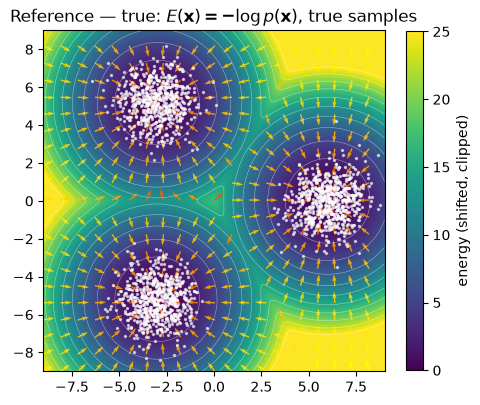

In [12]:
# Visual reference: the TRUE energy landscape (reuses plot_panel + target + x_true from §5/§6).
# Keep this panel in mind while scanning the grids below: a good learned landscape should show
# three basins in the same positions/depths/widths as this one, evenly covered by samples.
fig, ax = plt.subplots(figsize=(5.5, 5.5))
im = plot_panel(ax, target.energy, x_true, r"Reference — true: $E(\mathbf{x})=-\log p(\mathbf{x})$, true samples")
fig.colorbar(im, ax=ax, shrink=0.8, label="energy (shifted, clipped)")
plt.show()

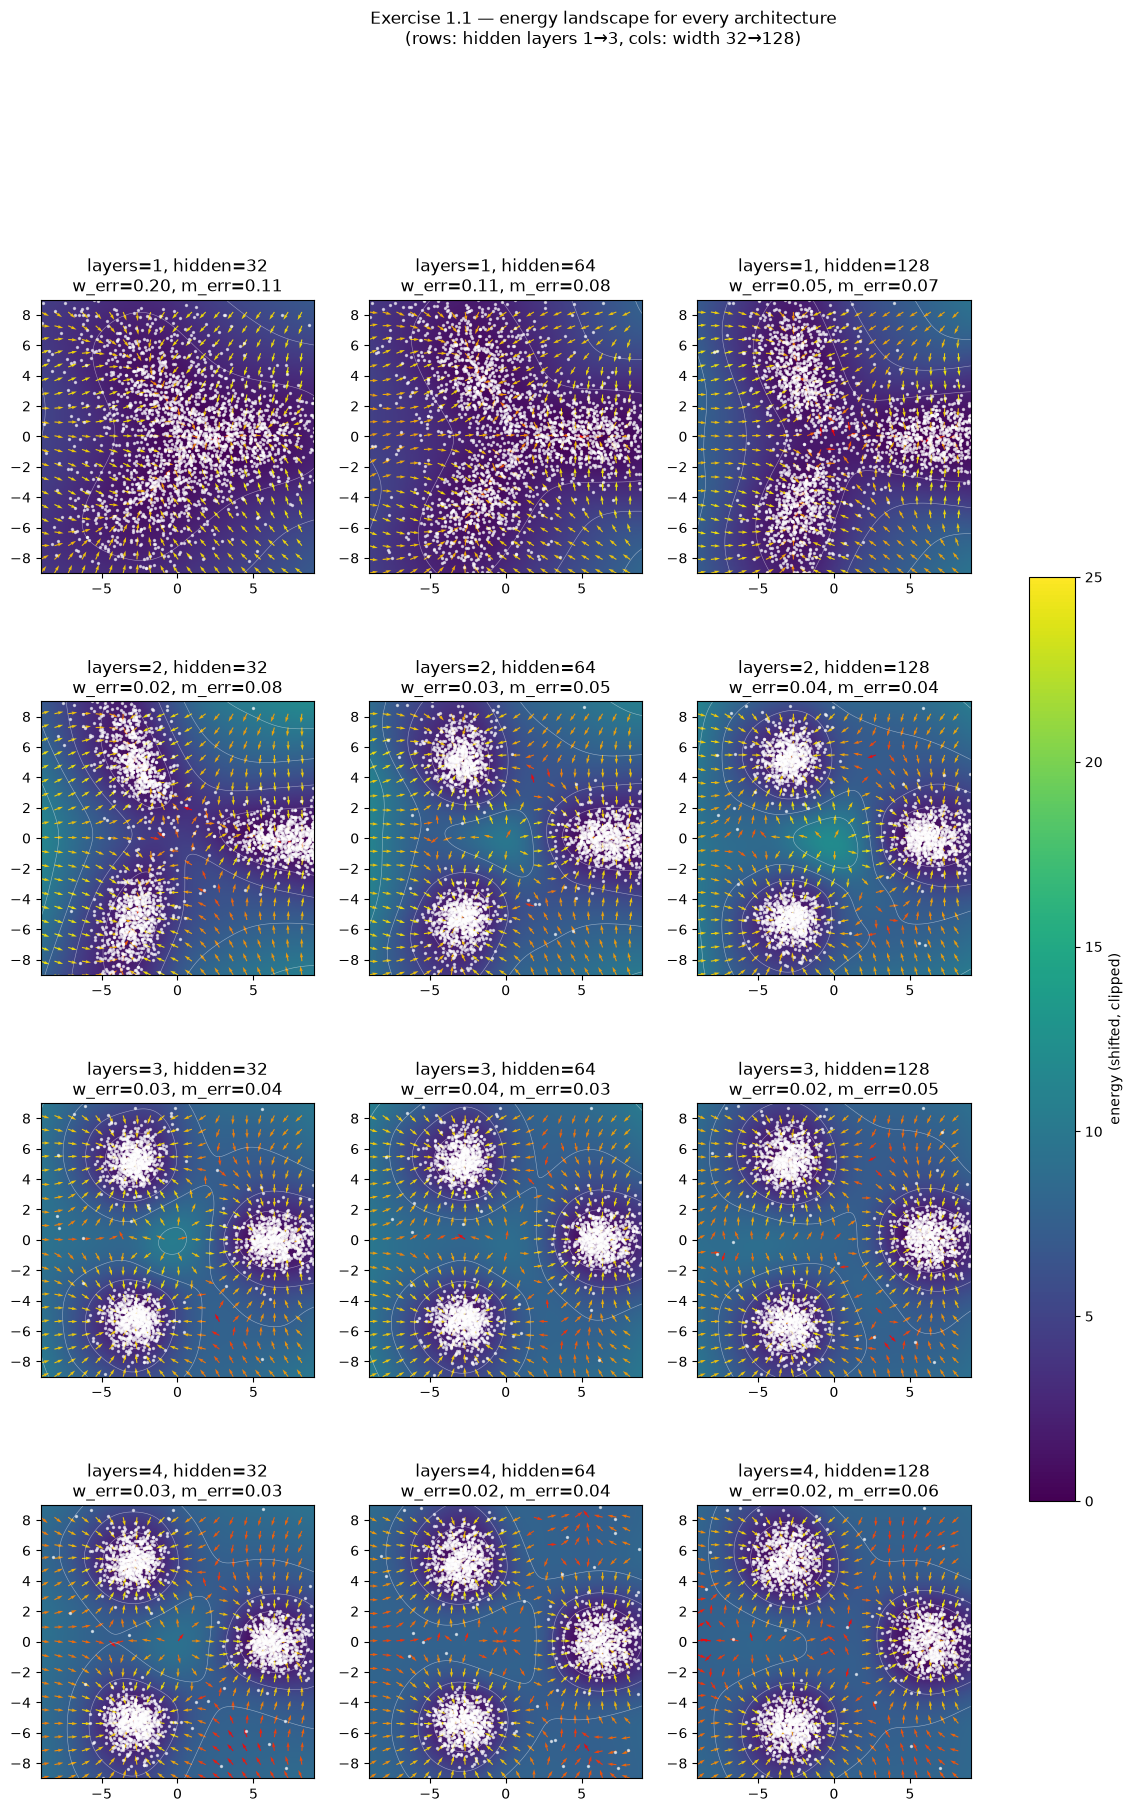

In [13]:
# Energy landscape + force field for ALL 9 architectures (reuses plot_panel from §6).
# Layout follows the natural sweep order: rows = n_hidden_layers (1 -> 3), cols = hidden (32 -> 128),
# so depth increases downward and width increases rightward.
arch_layers_sorted = sorted(df_arch["n_hidden_layers"].unique())
arch_hidden_sorted = sorted(df_arch["hidden"].unique())

fig, axes = plt.subplots(len(arch_layers_sorted), len(arch_hidden_sorted),
                         figsize=(5 * len(arch_hidden_sorted), 5 * len(arch_layers_sorted)))
for i, layers in enumerate(arch_layers_sorted):
    for j, hidden in enumerate(arch_hidden_sorted):
        idx = df_arch[(df_arch.n_hidden_layers == layers) & (df_arch.hidden == hidden)].index[0]
        m, row = models_arch[idx], df_arch.loc[idx]
        title = f"layers={layers}, hidden={hidden}\nw_err={row.weight_error_L1:.2f}, m_err={row.mean_error_rel:.2f}"
        im = plot_panel(axes[i, j], m["model"], m["x_gen"], title)
fig.colorbar(im, ax=axes, shrink=0.6, label="energy (shifted, clipped)")
fig.suptitle("Exercise 1.1 — energy landscape for every architecture\n(rows: hidden layers 1→3, cols: width 32→128)", y=1.01)
plt.show()

**Visual verdict (overrides the numeric pick above).**

* **1 hidden layer (any width) fails outright**: in the top row, all three panels merge the three true modes into a single diagonal blob instead of three separated basins — nothing like the reference plot. The scalar errors (`w_err` 0.05–0.11) don't look catastrophic in the table, but the shape is simply wrong: a case where the metric understates a real qualitative failure.
* **From 2 hidden layers on**, three basins appear in the right places (matching the reference above), so depth ≥ 2 is the minimum needed for this problem.
* **3 hidden layers** gives the cleanest result at every width tested: close-to-circular, well-separated basins with a force field that converges smoothly to each centre (very similar to the true reference), and no spurious contours/loops.
* **4 hidden layers** recovers the modes equally well but starts showing small artifacts away from the data (extra wiggles/loops in the far field) — consistent with the §6 remark that "far from the data the learned energy is less accurate": the extra capacity is not buying anything here, it's just adding noise.

**Chosen architecture: 3 hidden layers × 32 units.** It is the smallest network that already reaches the clean, artifact-free landscape, so it is carried into §1.2 below — overriding `best_arch`, which only won the numeric table on a tie-break with (3 layers, 128 units) and ranked worse on `mean_error_rel`.

In [14]:
# Architecture carried into §1.2, chosen by visual inspection (see markdown above), not by best_arch.
chosen_layers, chosen_hidden = 3, 32
print(f"Architecture used in §1.2: {chosen_layers} hidden layer(s) x {chosen_hidden} units "
      f"(visual pick, not the numeric best_arch = {best_layers} x {best_hidden})")

Architecture used in §1.2: 3 hidden layer(s) x 32 units (visual pick, not the numeric best_arch = 2 x 32)


#### 1.2 Hyperparameter sweep (using the architecture chosen by visual inspection in 1.1)

Fixing the architecture to the one chosen above (3 hidden layers × 32 units), now vary the Langevin noise level, the number of Langevin steps per training iteration, and the learning rate.

In [15]:
hparam_grid = {
    "noise_level":   [0.05, 0.1, 0.2],
    "n_steps":       [50, 100, 200],
    "learning_rate": [3e-4, 1e-3],
}
hparam_fixed = {
    "hidden": chosen_hidden,
    "n_hidden_layers": chosen_layers,
}

df_hparam, models_hparam = run_hparam_grid(
    hparam_grid, fixed=hparam_fixed,
    n_iters=600, n_gen=2000, seed=0, label="hparam", keep_models=True,
)

best_hp = df_hparam.loc[df_hparam["weight_error_L1"].idxmin()]
print(f"\nBest hyperparameters by weight_error_L1: noise_level={best_hp['noise_level']}, n_steps={int(best_hp['n_steps'])}, "
      f"learning_rate={best_hp['learning_rate']:.0e} "
      f"(weight_error_L1={best_hp['weight_error_L1']:.3f}, mean_error_rel={best_hp['mean_error_rel']:.3f})")
print("-> Treat this as a starting point only: inspect the energy-landscape plots below before trusting it.")

pretty_table(display_metrics(df_hparam, ["noise_level", "n_steps", "learning_rate"]),
             ["weight_error_L1", "mean_error_rel", "cov_error_rel"],
             "Exercise 1.2 — hyperparameter sweep (best architecture fixed)")

[hparam]  1/18  {'noise_level': 0.05, 'n_steps': 50, 'learning_rate': 0.0003}  -> weight_err=0.059, mean_err=0.092  (21.0s)
[hparam]  2/18  {'noise_level': 0.05, 'n_steps': 50, 'learning_rate': 0.001}  -> weight_err=0.038, mean_err=0.047  (21.0s)
[hparam]  3/18  {'noise_level': 0.05, 'n_steps': 100, 'learning_rate': 0.0003}  -> weight_err=0.058, mean_err=0.061  (37.9s)
[hparam]  4/18  {'noise_level': 0.05, 'n_steps': 100, 'learning_rate': 0.001}  -> weight_err=0.041, mean_err=0.032  (37.2s)
[hparam]  5/18  {'noise_level': 0.05, 'n_steps': 200, 'learning_rate': 0.0003}  -> weight_err=0.061, mean_err=0.070  (70.5s)
[hparam]  6/18  {'noise_level': 0.05, 'n_steps': 200, 'learning_rate': 0.001}  -> weight_err=0.050, mean_err=0.043  (70.4s)
[hparam]  7/18  {'noise_level': 0.1, 'n_steps': 50, 'learning_rate': 0.0003}  -> weight_err=0.035, mean_err=0.067  (20.8s)
[hparam]  8/18  {'noise_level': 0.1, 'n_steps': 50, 'learning_rate': 0.001}  -> weight_err=0.052, mean_err=0.044  (21.6s)
[hparam]  

,noise_level,n_steps,learning_rate,p_hq,weight_error_L1,mean_error_rel,cov_error_rel
12,0.200,50,0.000,0.802,0.012,0.048,0.760
14,0.200,100,0.000,0.798,0.019,0.033,0.761
17,0.200,200,0.001,0.927,0.019,0.025,0.235
15,0.200,100,0.001,0.918,0.034,0.037,0.183
8,0.100,100,0.000,0.815,0.034,0.049,0.761
6,0.100,50,0.000,0.841,0.035,0.067,0.780
1,0.050,50,0.001,0.987,0.038,0.047,0.411
11,0.100,200,0.001,0.943,0.039,0.029,0.160
3,0.050,100,0.001,0.981,0.041,0.032,0.370
9,0.100,100,0.001,0.955,0.048,0.041,0.169


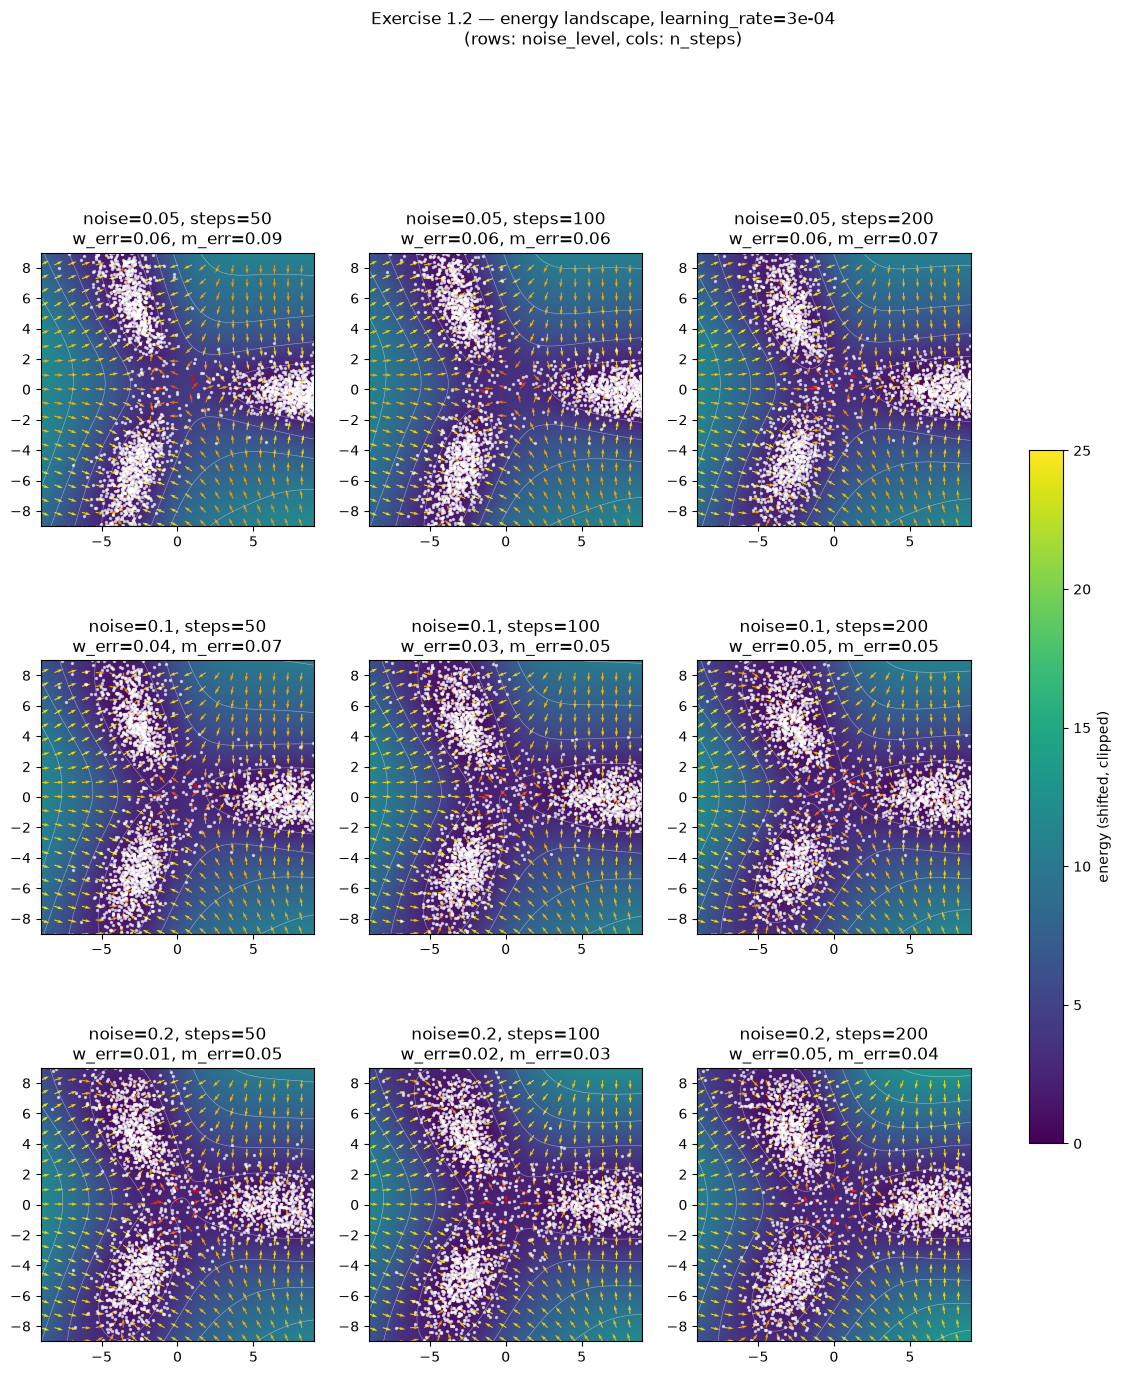

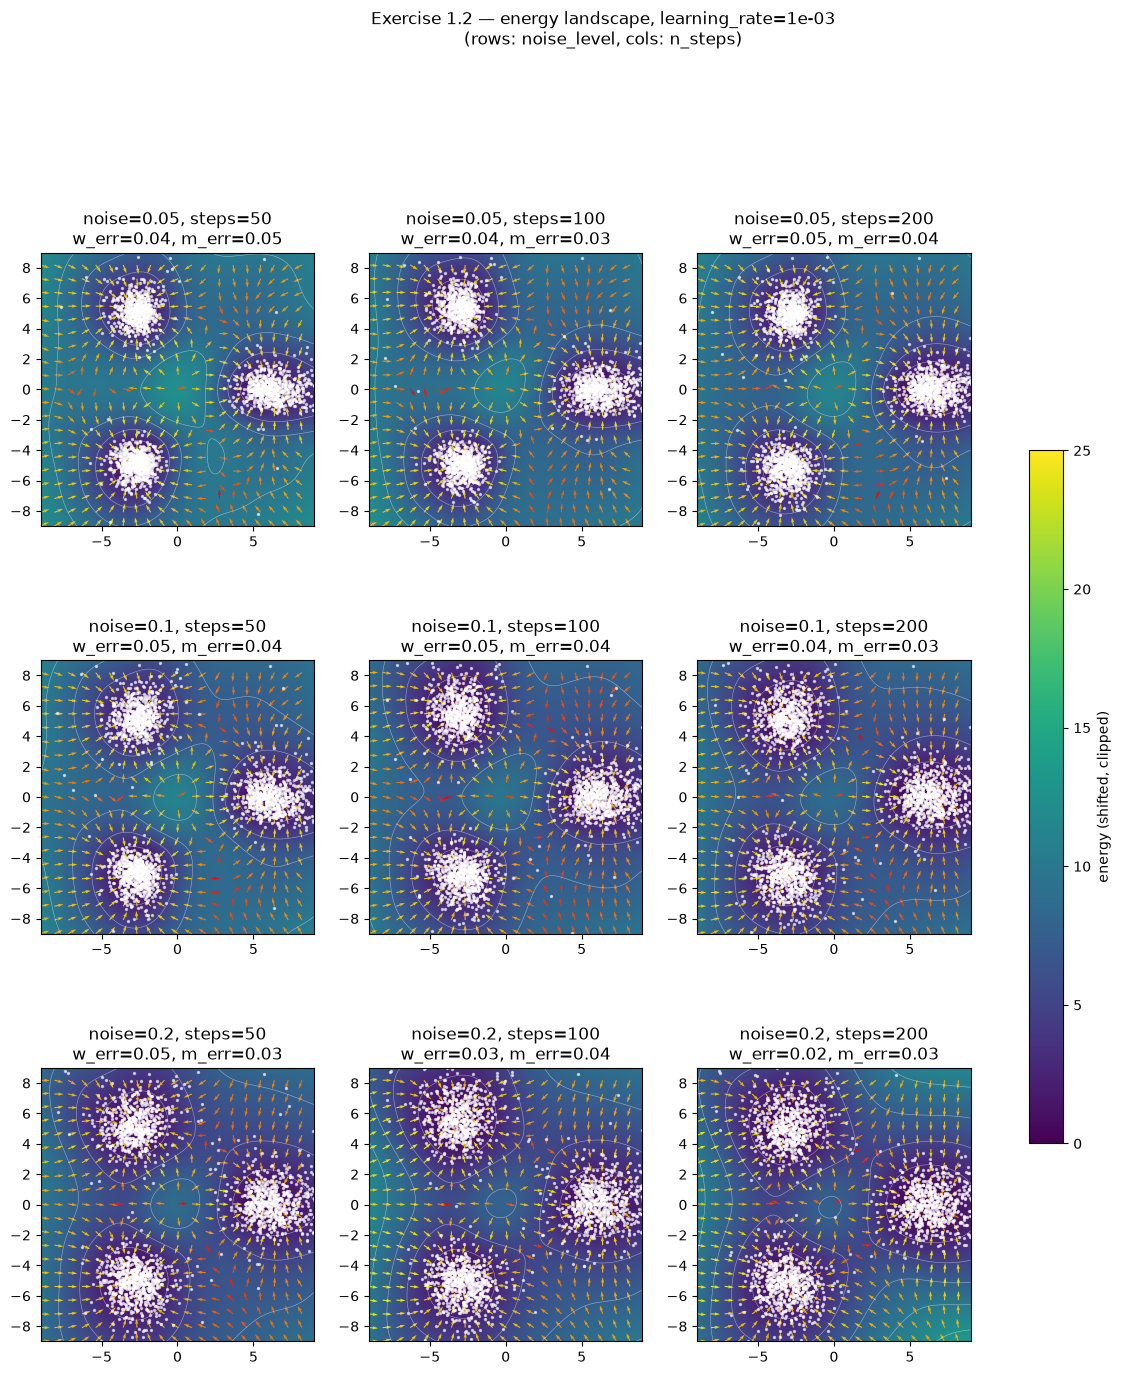

In [16]:
# Energy landscape + force field for ALL 18 hyperparameter configs (reuses plot_panel from §6).
# 3 (noise_level) x 3 (n_steps) x 2 (learning_rate) doesn't fit legibly in one figure, so we split
# into one figure per learning_rate; within each, rows = noise_level, cols = n_steps (both increasing).
hp_noise_sorted = sorted(df_hparam["noise_level"].unique())
hp_steps_sorted = sorted(df_hparam["n_steps"].unique())
hp_lr_sorted = sorted(df_hparam["learning_rate"].unique())

for lr in hp_lr_sorted:
    fig, axes = plt.subplots(len(hp_noise_sorted), len(hp_steps_sorted),
                             figsize=(5 * len(hp_steps_sorted), 5 * len(hp_noise_sorted)))
    for i, noise in enumerate(hp_noise_sorted):
        for j, ns in enumerate(hp_steps_sorted):
            idx = df_hparam[(df_hparam.noise_level == noise) & (df_hparam.n_steps == ns)
                             & (df_hparam.learning_rate == lr)].index[0]
            m, row = models_hparam[idx], df_hparam.loc[idx]
            title = f"noise={noise}, steps={int(ns)}\nw_err={row.weight_error_L1:.2f}, m_err={row.mean_error_rel:.2f}"
            im = plot_panel(axes[i, j], m["model"], m["x_gen"], title)
    fig.colorbar(im, ax=axes, shrink=0.6, label="energy (shifted, clipped)")
    fig.suptitle(f"Exercise 1.2 — energy landscape, learning_rate={lr:.0e}\n(rows: noise_level, cols: n_steps)", y=1.02)
    plt.show()

**Visual verdict (overrides the numeric pick above).**

* **`learning_rate = 3e-4` fails systematically** (first figure, all 9 panels): the top-left and bottom-left basins merge into one elongated vertical blob, and only the right-hand basin is correctly isolated. 600 training iterations simply aren't enough for this learning rate to finish carving the three wells.
* The numeric "best" row printed above (`noise=0.2, n_steps=50, learning_rate=3e-4`, `weight_error_L1=0.012`) belongs to exactly this failing group -- its low error is a coincidence of how the merged blob happens to split samples across the 3 nearest-mean bins, not a sign of a good model. This is the same metric-vs-visual mismatch seen in section 1.1.
* **`learning_rate = 1e-3` works well in all 9 panels** (second figure): three separated, close-to-circular basins matching the reference. Within this group, low `noise_level=0.05` occasionally leaves a small spurious low-energy ring unrelated to any true mode (e.g. `noise=0.05, n_steps=50/100`); raising `noise_level` to 0.1-0.2 and `n_steps` to 100-200 removes it and tightens the clusters further.

**Chosen hyperparameters: `noise_level=0.2`, `n_steps=200`, `learning_rate=1e-3`** -- visually the cleanest of the 18, and the one carried forward as the final training recipe (together with the architecture chosen in section 1.1) for the rest of the exercises below.

In [17]:
# Hyperparameters carried forward, chosen by visual inspection (see markdown above), not by best_hp.
chosen_noise_level, chosen_n_steps, chosen_learning_rate = 0.2, 200, 1e-3
print(f"Hyperparameters used as the final training recipe: noise_level={chosen_noise_level}, "
      f"n_steps={chosen_n_steps}, learning_rate={chosen_learning_rate:.0e} "
      f"(visual pick, not the numeric best_hp = noise={best_hp['noise_level']}, "
      f"n_steps={int(best_hp['n_steps'])}, lr={best_hp['learning_rate']:.0e})")

Hyperparameters used as the final training recipe: noise_level=0.2, n_steps=200, learning_rate=1e-03 (visual pick, not the numeric best_hp = noise=0.2, n_steps=50, lr=3e-04)


#### Summary table and CSV export

In [18]:
df_arch.to_csv("ex1_architecture_grid.csv", index=False)
df_hparam.to_csv("ex1_hyperparam_grid.csv", index=False)

df_all = pd.concat(
    [df_arch.assign(sweep="architecture"), df_hparam.assign(sweep="hyperparameters")],
    ignore_index=True,
)
df_all.to_csv("ex1_full_grid_results.csv", index=False)
print("Saved: ex1_architecture_grid.csv, ex1_hyperparam_grid.csv, ex1_full_grid_results.csv")
print("(the CSVs keep every column, including n_params/final_loss/train_seconds, for the record)")

best_overall = df_all.loc[df_all["weight_error_L1"].idxmin()]
print("\nBest overall configuration by weight_error_L1 (a numeric starting point, not the final verdict):")
print(best_overall[["sweep", "n_hidden_layers", "hidden", "learning_rate",
                     "noise_level", "n_steps", "p_hq", "weight_error_L1", "mean_error_rel", "cov_error_rel"]])

pretty_table(display_metrics(df_all, ["sweep", "n_hidden_layers", "hidden", "learning_rate", "noise_level", "n_steps"]),
             ["weight_error_L1", "mean_error_rel", "cov_error_rel"],
             "Exercise 1 — full architecture + hyperparameter sweep")

Saved: ex1_architecture_grid.csv, ex1_hyperparam_grid.csv, ex1_full_grid_results.csv
(the CSVs keep every column, including n_params/final_loss/train_seconds, for the record)

Best overall configuration by weight_error_L1 (a numeric starting point, not the final verdict):
sweep              hyperparameters
n_hidden_layers                  3
hidden                          32
learning_rate               0.0003
noise_level                    0.2
n_steps                         50
p_hq                         0.802
weight_error_L1           0.011638
mean_error_rel             0.04819
cov_error_rel             0.759824
Name: 24, dtype: object


,sweep,n_hidden_layers,hidden,learning_rate,noise_level,n_steps,p_hq,weight_error_L1,mean_error_rel,cov_error_rel
24,hyperparameters,3,32,0.000,0.200,50,0.802,0.012,0.048,0.760
3,architecture,2,32,0.001,0.100,60,0.873,0.016,0.075,0.686
8,architecture,3,128,0.001,0.100,60,0.963,0.016,0.049,0.116
26,hyperparameters,3,32,0.000,0.200,100,0.798,0.019,0.033,0.761
10,architecture,4,64,0.001,0.100,60,0.968,0.019,0.037,0.112
29,hyperparameters,3,32,0.001,0.200,200,0.927,0.019,0.025,0.235
11,architecture,4,128,0.001,0.100,60,0.967,0.022,0.058,0.139
9,architecture,4,32,0.001,0.100,60,0.972,0.030,0.033,0.154
4,architecture,2,64,0.001,0.100,60,0.944,0.032,0.051,0.205
6,architecture,3,32,0.001,0.100,60,0.972,0.033,0.039,0.230


### 2. **Energy Values**

The positive examples (real data) have lower energy than the negative examples because this is encouraged by the contrastive loss function. The idea is that, by assigning low energy to the positive examples, the network learns where the low-energy regions of the data distribution are, so that new samples can be generated in those regions.

At the same time, it is important to increase the energy of the negative samples so that the network does not simply assign low energy to the entire space. This helps the model learn an energy landscape where the real data corresponds to low-energy regions, while incorrect regions have higher energy. During sampling, Langevin dynamics can then move new samples towards these lower-energy regions where the real data distribution lies.


### 3. **Annealing Steps**

If the annealing steps are not performed at the beginning, the energy landscape may not be well defined in regions with little data. As a result, the gradient in those regions may not provide a useful direction for the samples. Since the samples are initialized randomly, they may get stuck in low-density regions and fail to reach the modes of the target distribution. Annealing helps make the energy landscape smoother and provides a better path for the samples to reach the low-energy regions.

### 4. **Number of Langevin Steps**

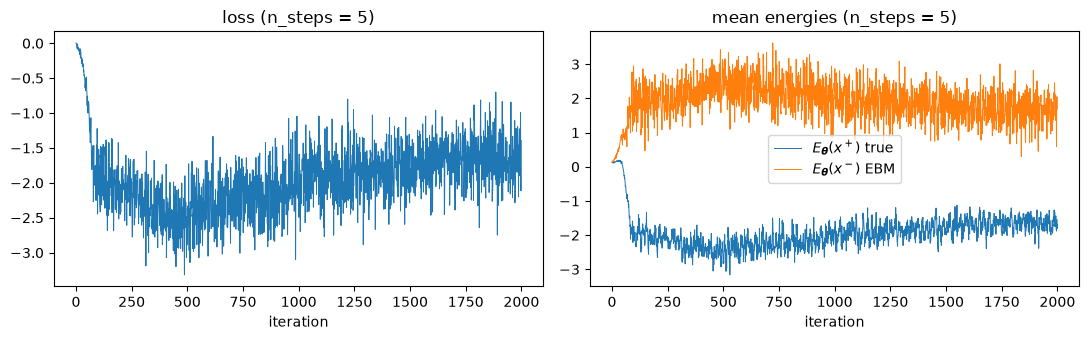

,p_hq,n_modes_found,weight_error_L1,mean_error_rel,cov_error_rel
long-run (section 5 generation),0.9695,3.0,0.037820,0.029341,0.217089
short-run (5 steps),0.2920,3.0,0.073059,0.018989,1.083060


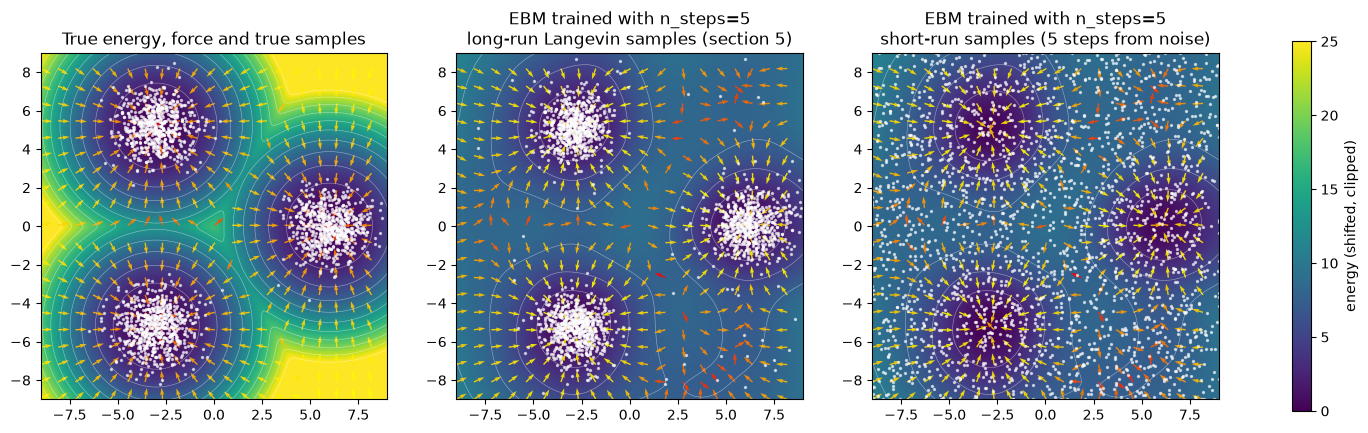

In [19]:
# ---- Exercise 4: train with n_steps = 5 (short-run Langevin) ----
# Uses the best model from Exercise 1: architecture chosen visually in 1.1 (chosen_layers hidden
# layers x chosen_hidden units) and hyperparameters chosen visually in 1.2 (noise_level=chosen_noise_level,
# learning_rate=chosen_learning_rate). Only n_steps changes, from the chosen 200 down to 5, as required
# by this exercise.
model_sr = FlexEnergyNet(hidden=chosen_hidden, n_hidden_layers=chosen_layers).to(device)
history_sr = train_ebm(
    model_sr, x_data.to(device),
    n_iters=2000, n_steps=5, noise_level=chosen_noise_level, learning_rate=chosen_learning_rate, seed=0,
)

# training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history_sr["loss"], lw=0.7); ax[0].set_title("loss (n_steps = 5)"); ax[0].set_xlabel("iteration")
ax[1].plot(history_sr["E_pos"], lw=0.7, label=r"$E_{\boldsymbol{\theta}}(x^+)$ true")
ax[1].plot(history_sr["E_neg"], lw=0.7, label=r"$E_{\boldsymbol{\theta}}(x^-)$ EBM")
ax[1].set_title("mean energies (n_steps = 5)"); ax[1].set_xlabel("iteration"); ax[1].legend()
plt.tight_layout(); plt.show()

# (a) samples from the same generation procedure as section 5 (long, annealed chains from noise)
x_gen_long = generate_ebm_samples(model_sr, n_gen=2000, seed=0)

# (b) samples from the short-run sampler used in training: only 5 steps (noise_level = chosen_noise_level) from noise
model_sr.eval()
torch.manual_seed(0)
x_short = (torch.rand(2000, 2, device=device) * 2 - 1) * BOX
x_short = langevin(model_sr, x_short, n_steps=5, noise_level=chosen_noise_level).cpu()
model_sr.train()

# error measures of section 7 for both samplers
metrics_sr = pd.DataFrame({"long-run (section 5 generation)": evaluate_ebm(x_gen_long, target),
                           "short-run (5 steps)": evaluate_ebm(x_short, target)}).T
display(metrics_sr)

# energy landscape + force field (colormap + arrows), as in section 6
x_true_sr = target.sample(2000)
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
plot_panel(axes[0], target.energy, x_true_sr, "True energy, force and true samples")
plot_panel(axes[1], model_sr, x_gen_long, "EBM trained with n_steps=5\nlong-run Langevin samples (section 5)")
im = plot_panel(axes[2], model_sr, x_short, "EBM trained with n_steps=5\nshort-run samples (5 steps from noise)")
fig.colorbar(im, ax=axes, shrink=0.8, label="energy (shifted, clipped)")
plt.show()

**Interpretation (Exercise 4):**

* **The learned energy is still reasonable.** The landscape has three basins at the right places, and long chains (the generation of §5) give good samples: `p_hq` 0.970 and `cov_error_rel` 0.217.
* **The 5-step sampler does not work as a generator.** Five steps from uniform noise leave the samples spread over the whole box: `p_hq` 0.292, close to the ≈ 0.26 of uniform samples, and `cov_error_rel` 1.08.
* **The two mean energies never meet.** $E_\theta(x^+)$ goes down to about −2.3 and $E_\theta(x^-)$ up to about +2.3 in the first 500 iterations. After that they approach each other slowly, but at the end of training they are still far apart (about −1.7 and +1.7), so the negative samples never become similar to the data.

* With `noise_level = 0.2`, reaching the data in five steps would need very large gradients, which the regulariser `alpha` prevents by keeping the energies bounded.
* The replay buffer is persistent: each chain accumulates steps and this lets the chains drift towards the basins, but it is still too short to converge and the negative samples stay spread over the box.
* With negative samples spread everywhere, training acts as a contrast between data and noise: the energy is lowered on the data and raised elsewhere.
  
In the paper the chains always start from noise (no persistent buffer) and the step size is large enough for a short chain to reach the data, which is why a short-run generator is learned there.

### 5. **No Replay Buffer**

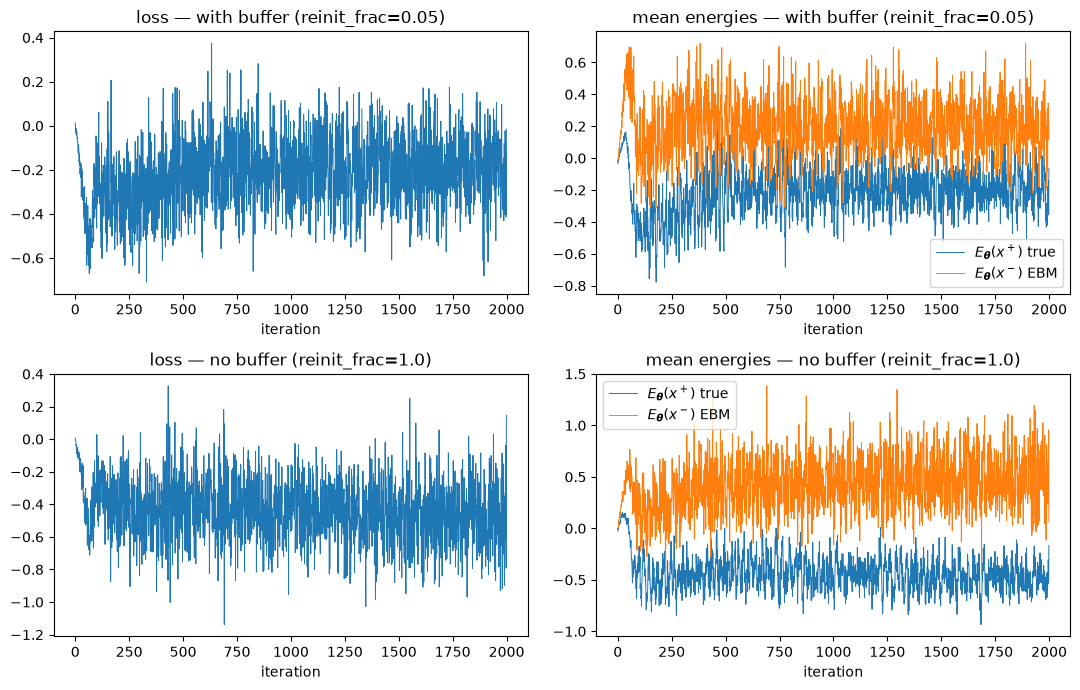

,p_hq,n_modes_found,weight_error_L1,mean_error_rel,cov_error_rel,loss_std_last500
with buffer (reinit_frac=0.05),0.9385,3.0,0.032321,0.027943,0.203615,0.152313
no buffer (reinit_frac=1.0),0.9395,3.0,0.029094,0.013327,0.155312,0.197803


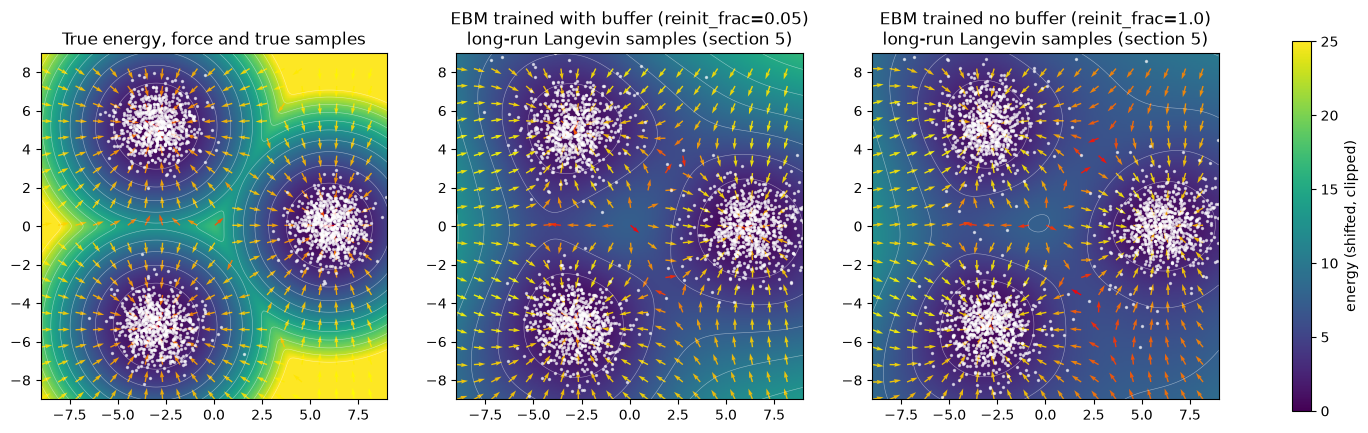

In [20]:
runs_buf = {}
for name, rf in [("with buffer (reinit_frac=0.05)", 0.05), ("no buffer (reinit_frac=1.0)", 1.0)]:
    torch.manual_seed(0)
    m = FlexEnergyNet(hidden=chosen_hidden, n_hidden_layers=chosen_layers).to(device)
    h = train_ebm(m, x_data.to(device), n_iters=2000, n_steps=chosen_n_steps,
                  noise_level=chosen_noise_level, learning_rate=chosen_learning_rate,
                  reinit_frac=rf, seed=0)
    runs_buf[name] = {"model": m, "history": h, "x_gen": generate_ebm_samples(m, n_gen=2000, seed=0)}

# training curves: one row per run
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, r) in zip(axes, runs_buf.items()):
    h = r["history"]
    row[0].plot(h["loss"], lw=0.7); row[0].set_title(f"loss — {name}"); row[0].set_xlabel("iteration")
    row[1].plot(h["E_pos"], lw=0.7, label=r"$E_{\boldsymbol{\theta}}(x^+)$ true")
    row[1].plot(h["E_neg"], lw=0.7, label=r"$E_{\boldsymbol{\theta}}(x^-)$ EBM")
    row[1].set_title(f"mean energies — {name}"); row[1].set_xlabel("iteration"); row[1].legend()
plt.tight_layout(); plt.show()

# error measures of section 7, plus the spread of the loss over the last 500 iterations
metrics_buf = pd.DataFrame({name: {**evaluate_ebm(r["x_gen"], target),
                                   "loss_std_last500": float(np.std(r["history"]["loss"][-500:]))}
                            for name, r in runs_buf.items()}).T
display(metrics_buf)

# energy landscape + force field, as in section 6
x_true_buf = target.sample(2000)
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
plot_panel(axes[0], target.energy, x_true_buf, "True energy, force and true samples")
for ax, (name, r) in zip(axes[1:], runs_buf.items()):
    im = plot_panel(ax, r["model"], r["x_gen"], f"EBM trained {name}\nlong-run Langevin samples (section 5)")
fig.colorbar(im, ax=axes, shrink=0.8, label="energy (shifted, clipped)")
plt.show()

**Interpretation (Exercise 5).**

* **Training stays stable in both cases.** Neither run diverges: in both, the two mean energies settle after about 100 iterations and stay aprox. constant for the rest of the training.
* **Without the buffer the training is has more noise.** The gap between the two mean energies is larger (around −0.45 and +0.45, against −0.2 and +0.2 with the buffer), the loss settles around −0.45 instead of −0.2, and it fluctuates more. $E_\theta(x^-)$ also shows occasional spikes above +1.
* **The final model is not worse.** Both landscapes show three well-separated basins in the right places, and the samples are of similar quality: `p_hq` 0.940 against 0.939, and `cov_error_rel` 0.155 without the buffer against 0.204 with it. With a single seed this difference in covariance is not conclusive.

**Why.** Without the buffer every negative chain starts from uniform noise and has only the Langevin steps of one iteration to reach the model distribution. With the configuration chosen in §1.2 (`n_steps = 200`, `noise_level = 0.2`) this is long enough to reach the basins, so the negative samples are already close to the data. The chains are still not fully converged, and a few of them probably remain far from the modes, which would explain the larger energy gap.

With the buffer each chain continues from where it stopped in a previous iteration, so the negative samples are closer to equilibrium: the two mean energies are closer together and the loss is nearer to zero and less noisy.

So in this setting the replay buffer improves the stability of the training signal but is not needed to obtain a good model, because the chains are already long. The buffer is most useful when one wants to train with few Langevin steps per iteration.

### 6. **Unequal Weights**

,mode 0,mode 1,mode 2,weight_error_L1
true weights,0.750,0.188,0.062,0.000
short (200 steps),0.346,0.326,0.328,0.808
medium (2000 steps),0.397,0.323,0.280,0.706
long (20000 steps),0.546,0.308,0.146,0.408


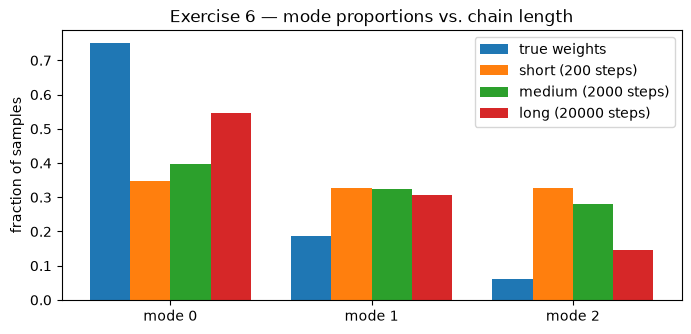

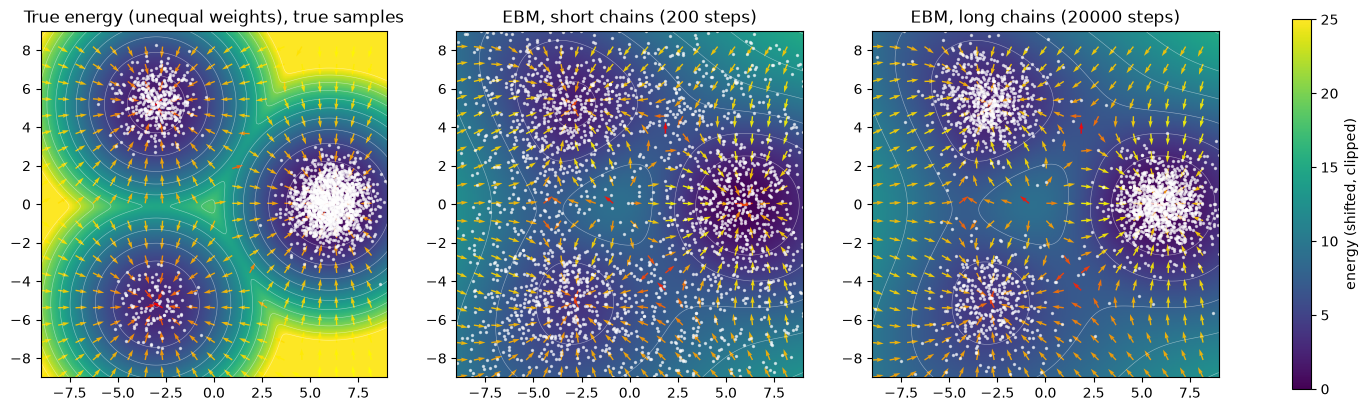

In [21]:
target_uw = GaussianMixture2D(K=K, radius=radius, std=standard_deviation, weights=[3 / 4, 3 / 16, 1 / 16])
torch.manual_seed(0)
x_data_uw = target_uw.sample(20_000)

torch.manual_seed(0)
model_uw = FlexEnergyNet(hidden=chosen_hidden, n_hidden_layers=chosen_layers).to(device)
history_uw = train_ebm(model_uw, x_data_uw.to(device), n_iters=2000, n_steps=chosen_n_steps,
                       noise_level=chosen_noise_level, learning_rate=chosen_learning_rate, seed=0)

def sample_from_noise(model, n_steps, noise_level, n_gen=2000, seed=0):
    torch.manual_seed(seed)
    x = (torch.rand(n_gen, 2, device=device) * 2 - 1) * BOX
    return langevin(model, x, n_steps=n_steps, noise_level=noise_level).cpu()

model_uw.eval()
runs_uw = {
    "short (200 steps)":   sample_from_noise(model_uw, 200, 0.1),
    "medium (2000 steps)": sample_from_noise(model_uw, 2000, 0.1),
    "long (20000 steps)":  sample_from_noise(model_uw, 20000, 0.1),
}

# fraction of samples assigned to each mode, against the true weights
def mode_weights(x, tgt):
    p_hq, w_hq, _, _ = check_gaussian_mixture(x, tgt.means, tgt.std, 3.0)
    return (w_hq / p_hq).numpy()

rows = {"true weights": target_uw.weights.numpy(), **{name: mode_weights(x, target_uw) for name, x in runs_uw.items()}}
df_uw = pd.DataFrame(rows, index=[f"mode {k}" for k in range(K)]).T
df_uw["weight_error_L1"] = (df_uw - df_uw.loc["true weights"]).abs().sum(axis=1)
display(df_uw.round(3))

# grouped bars: one group per mode, one bar per sampler
w = 0.8 / len(rows)
plt.figure(figsize=(8, 3.5))
for i, (name, vals) in enumerate(rows.items()):
    plt.bar(np.arange(K) + i * w, vals, w, label=name)
plt.xticks(np.arange(K) + 0.4 - w / 2, [f"mode {k}" for k in range(K)])
plt.ylabel("fraction of samples"); plt.legend(); plt.title("Exercise 6 — mode proportions vs. chain length")
plt.show()

# energy landscape + force field, as in section 6
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
plot_panel(axes[0], target_uw.energy, target_uw.sample(2000), "True energy (unequal weights), true samples")
plot_panel(axes[1], model_uw, runs_uw["short (200 steps)"], "EBM, short chains (200 steps)")
im = plot_panel(axes[2], model_uw, runs_uw["long (20000 steps)"], "EBM, long chains (20000 steps)")
fig.colorbar(im, ax=axes, shrink=0.8, label="energy (shifted, clipped)")
plt.show()

**Interpretation (Exercise 6).**

* **Short chains started from noise do not reproduce the proportions.** After 200 steps each mode receives almost exactly one third of the samples (0.346 / 0.326 / 0.328 against the true 0.750 / 0.188 / 0.062, `weight_error_L1` 0.808), and many samples have not reached any mode yet. Each chain slides down into the nearest basin, so the split reflects where the uniform initial points fall.
* **Longer chains do better, but slowly.** The error falls to 0.706 after 2000 steps and to 0.408 after 20 000. The samples move in the right direction (mode 0 grows from 0.346 to 0.546 and mode 2 falls from 0.328 to 0.146), but even 20 000 steps are far from equilibrium: mode 2 still has more than twice its true weight, and mode 1 has barely changed (0.326 → 0.308, against a true 0.188).

**Why.** In an energy-based model the weights are encoded in the depth of the wells. This information only affects the samples if the chains can move from one mode to another, and for that they must cross the high-energy region between modes. If the mode is really deep, it is going to be harder to scape from it, so the mixing time of Langevin dynamics is much longer than the time needed to fall into a well. This also explains the order in which the modes are corrected: the shallowest well (mode 2) has the lowest barrier, so it loses samples first, while the deeper well of mode 1 keeps its excess samples for much longer.


### 7. **The Langevin dynamics at temperature $T$**

### 8. **Score Matching: Replace contrastive divergence by *denoising score matching***